<a href="https://colab.research.google.com/github/But-Vladyslava/Machine-Learning-Uni-/blob/main/%D0%9B%D0%91_2_3_%D0%91%D1%83%D1%82%2C_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Лабораторна робота 2_3**

Зчитати таблицю
Коефіцієнт народжуваності в регіонах України (1950—2019)
https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C

Провести аналіз даних за стандартною схемою
та побудувати 5 графіків

# 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Зчитування даних

In [5]:
import urllib.request
import pandas as pd

url = "https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8"
headers = {'User-Agent': 'Mozilla/5.0'}
req = urllib.request.Request(url, headers=headers)

with urllib.request.urlopen(req) as response:
    tables = pd.read_html(response.read(), match="Коефіцієнт народжуваності")

df = tables[0]
display(df.head())

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—


# 3. Первинний аналіз та дослідження даних

In [6]:
print("Розмір датасету:", df.shape)
print("\nІнформація про датасет:")
df.info()

Розмір датасету: (28, 9)

Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     int64  
 5   2000    28 non-null     int64  
 6   2012    28 non-null     int64  
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(3), int64(3), object(3)
memory usage: 2.1+ KB


# 4. Переведення типів даних та очищення

In [7]:
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace('—', 'nan').str.replace(',', '.'), errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     int64  
 5   2000    28 non-null     int64  
 6   2012    28 non-null     int64  
 7   2014    26 non-null     float64
 8   2019    24 non-null     float64
dtypes: float64(5), int64(3), object(1)
memory usage: 2.1+ KB


# 5. Аналіз та обробка пропущених значень

In [8]:
print("Кількість пропущених значень у кожному стовпчику:")
print(df.isnull().sum())

Кількість пропущених значень у кожному стовпчику:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      2
2019      4
dtype: int64


# 6. Описова статистика

In [9]:
display(df.describe())

,1950,1960,1970,1990,2000,2012,2014,2019
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000,26.000000,24.000000
mean,230.923077,207.481481,155.851852,130.428571,82.071429,116.464286,111.423077,80.208333
std,28.220451,29.360322,18.703565,15.278716,15.568079,16.362745,20.116010,14.503310
min,186.000000,163.000000,127.000000,108.000000,61.000000,94.000000,51.000000,60.000000
25%,211.500000,186.500000,144.000000,122.250000,70.750000,104.500000,102.250000,68.000000
50%,226.000000,204.000000,152.000000,126.000000,78.500000,114.500000,111.500000,79.000000
75%,246.000000,220.500000,163.000000,140.500000,89.500000,122.500000,121.000000,88.000000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000,148.000000,110.000000


# 7. Візуалізація даних

Графік 1.  Загальна динаміка народжуваності


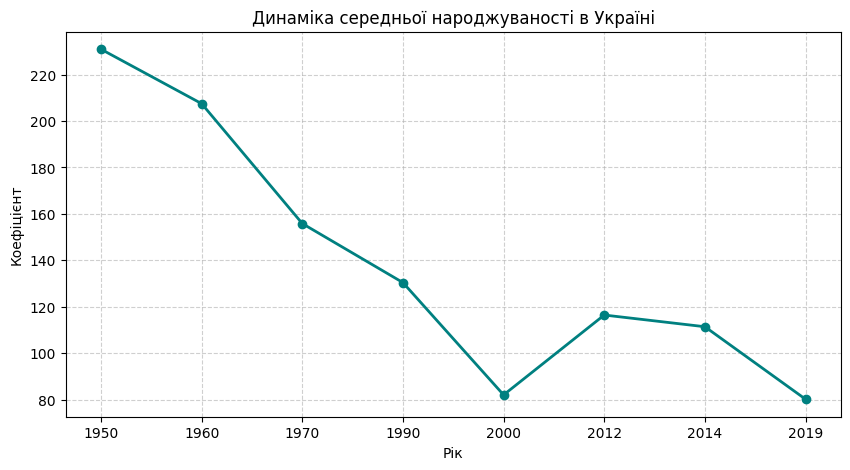

In [12]:
plt.figure(figsize=(10, 5))
years = ['1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']
mean_values = [df[col].mean() for col in years]
plt.plot(years, mean_values, marker='o', color='teal', linewidth=2)
plt.title('Динаміка середньої народжуваності в Україні')
plt.xlabel('Рік')
plt.ylabel('Коефіцієнт')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Графік 2.  Регіональний розподіл за 2019 рік

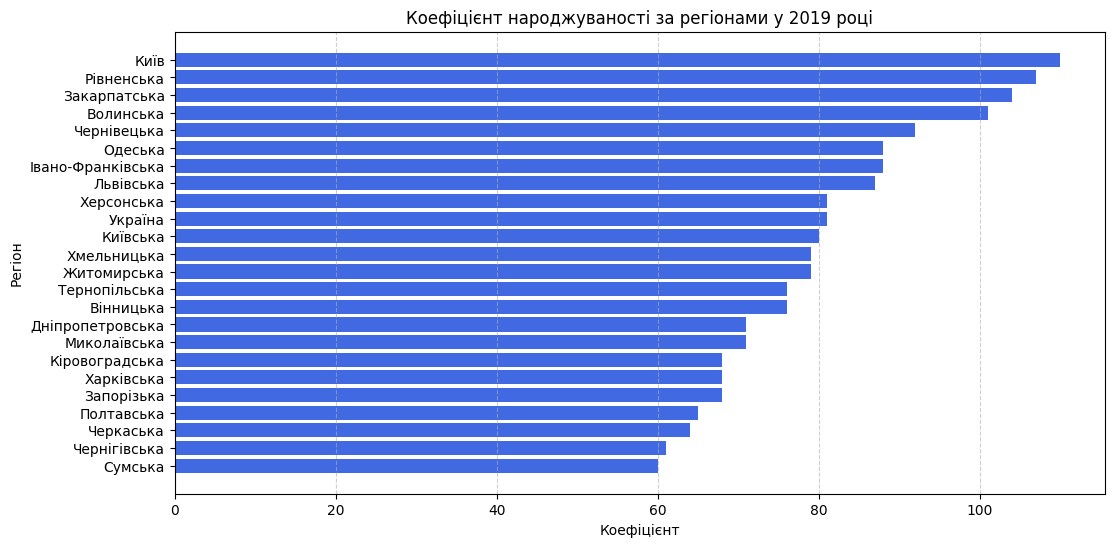

In [14]:
plt.figure(figsize=(12, 6))
top_10 = df[['Регіон', '2019']].dropna().sort_values(by='2019', ascending=True)
plt.barh(top_10['Регіон'], top_10['2019'], color='royalblue')
plt.title('Коефіцієнт народжуваності за регіонами у 2019 році')
plt.xlabel('Коефіцієнт')
plt.ylabel('Регіон')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

Динаміка народжуваності в регіонах України

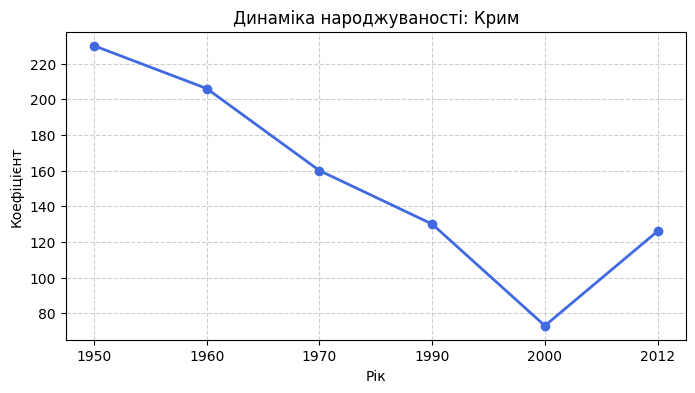

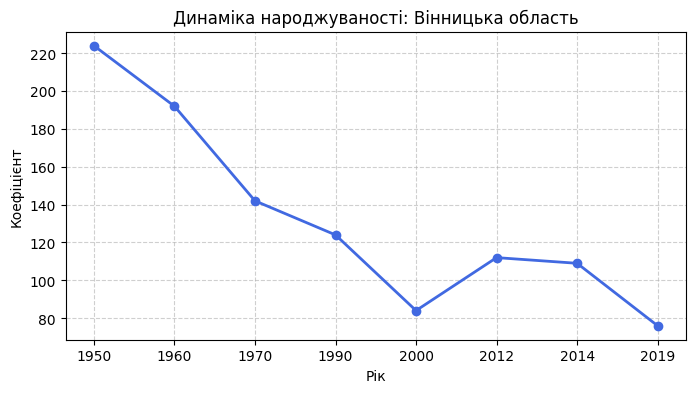

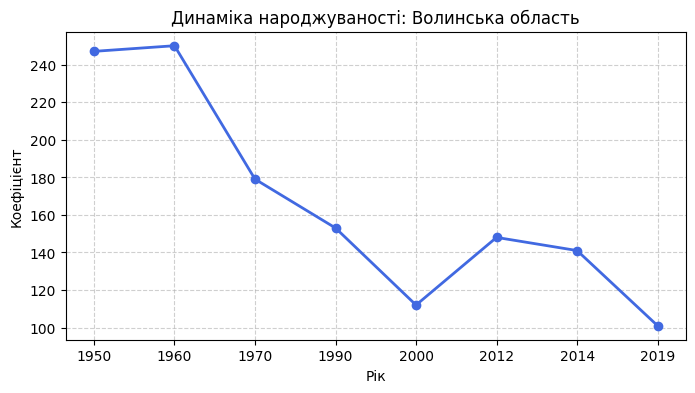

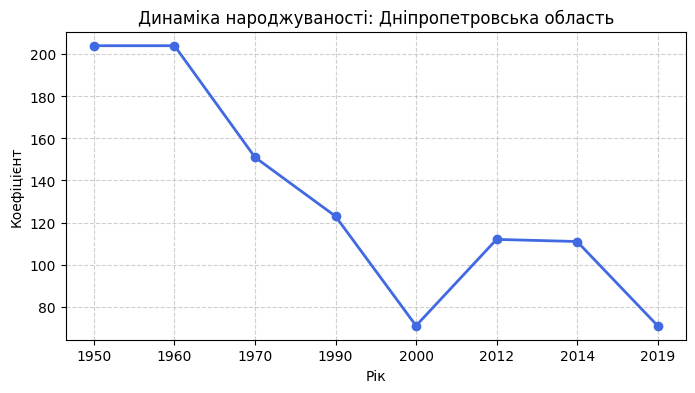

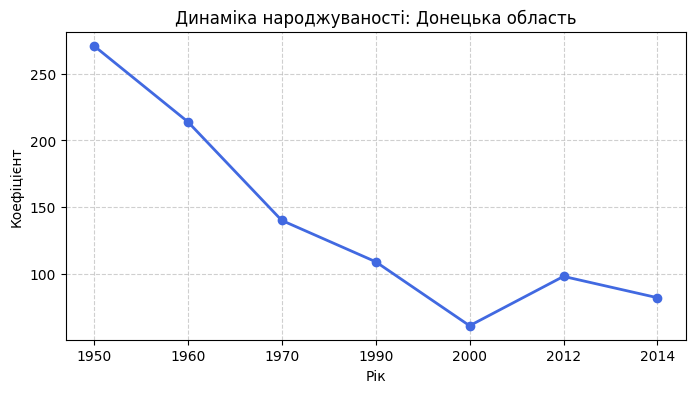

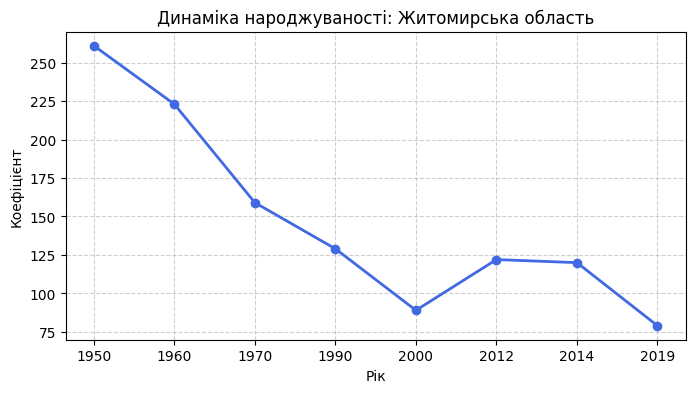

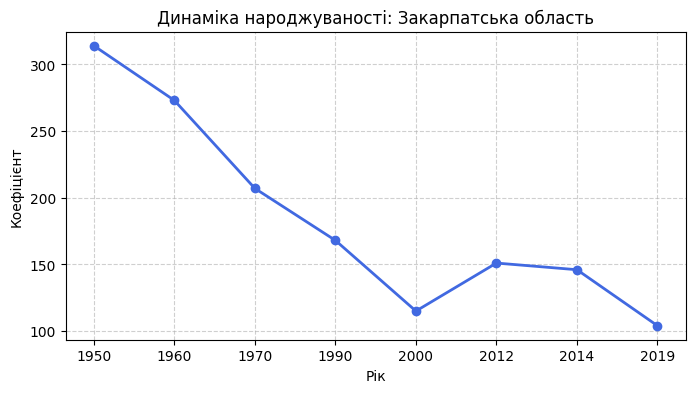

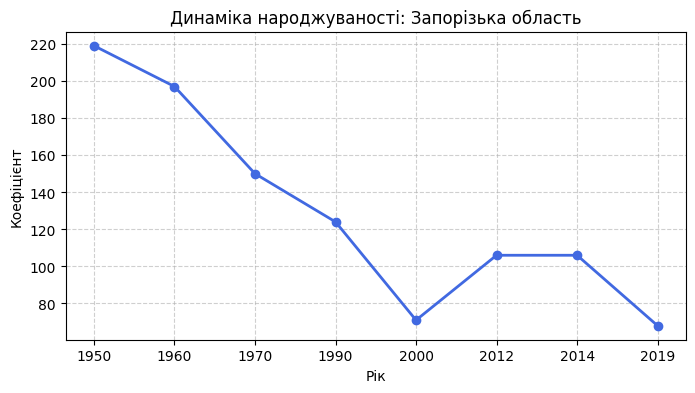

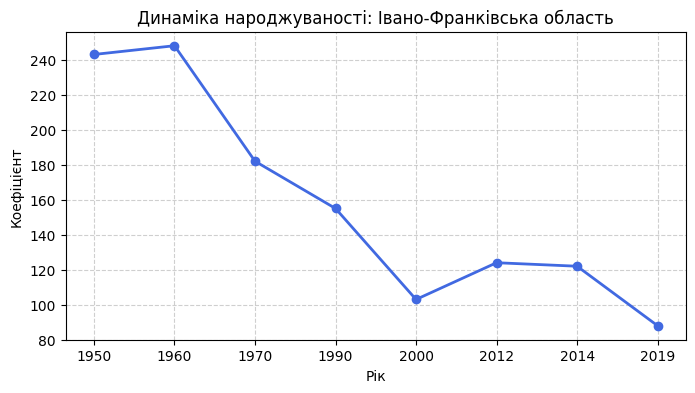

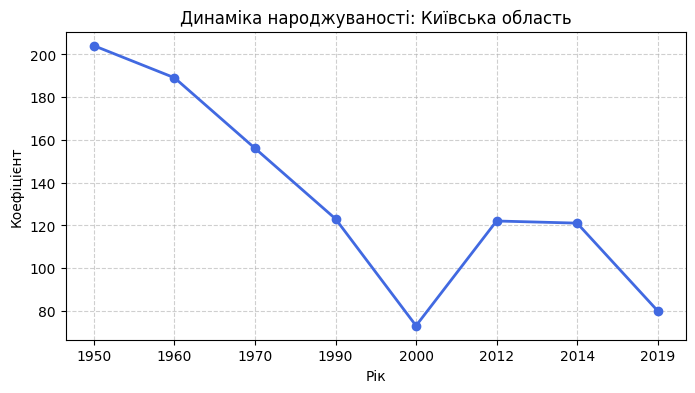

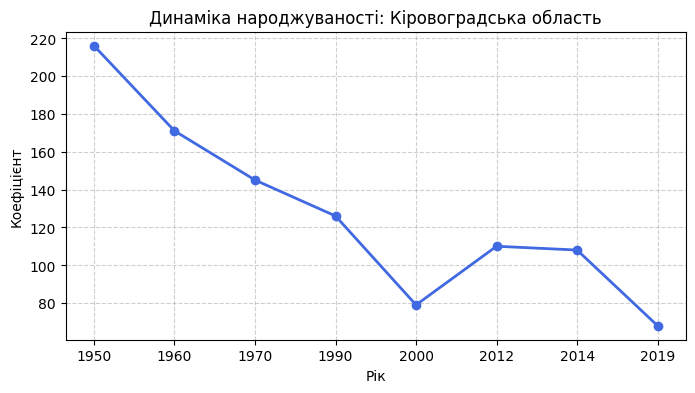

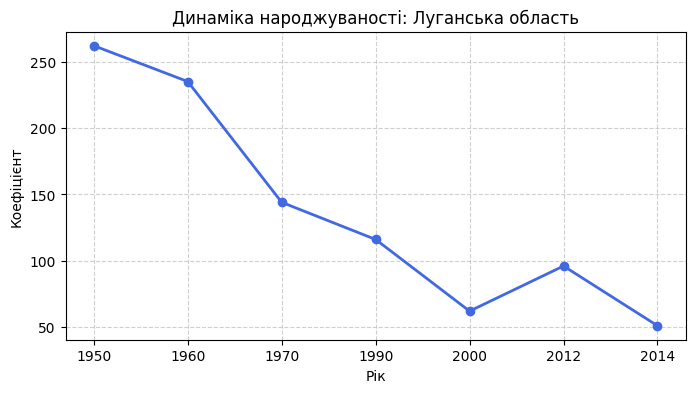

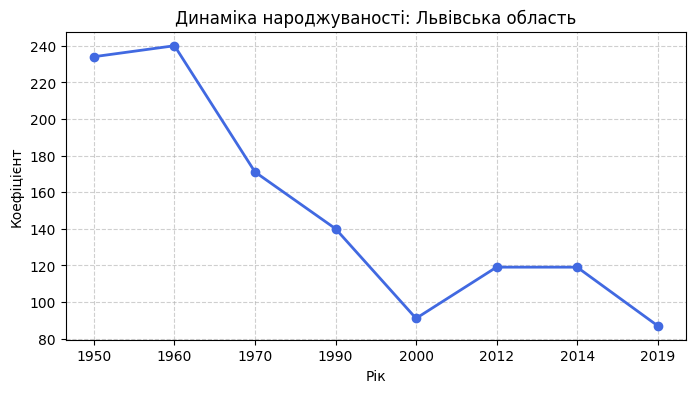

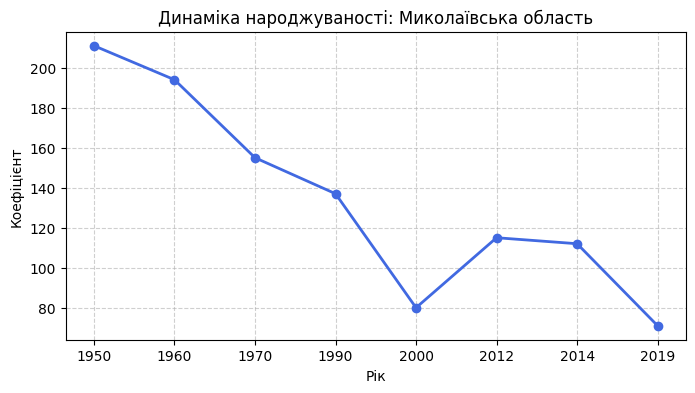

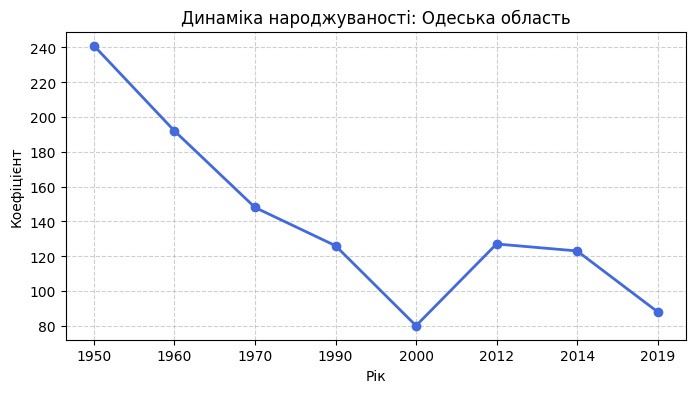

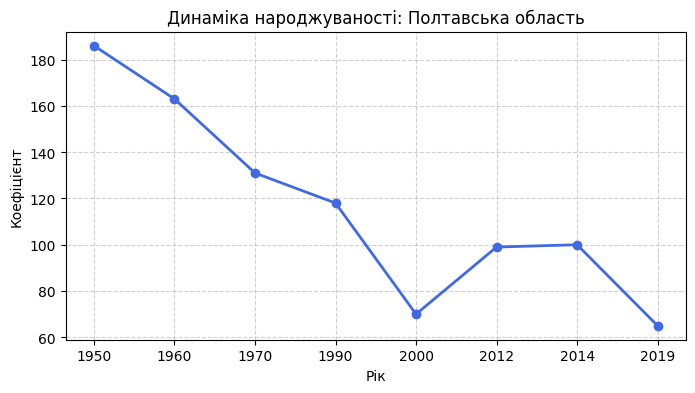

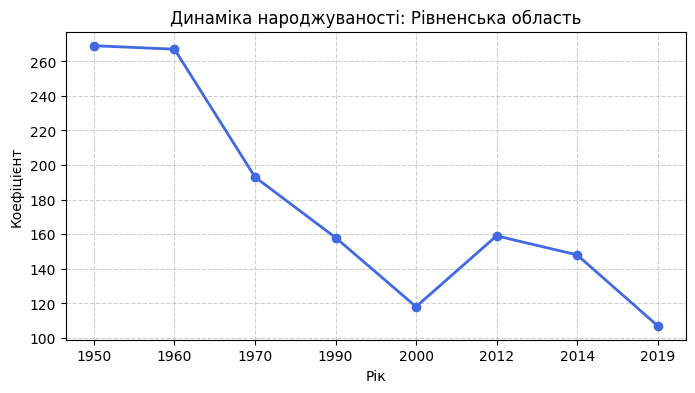

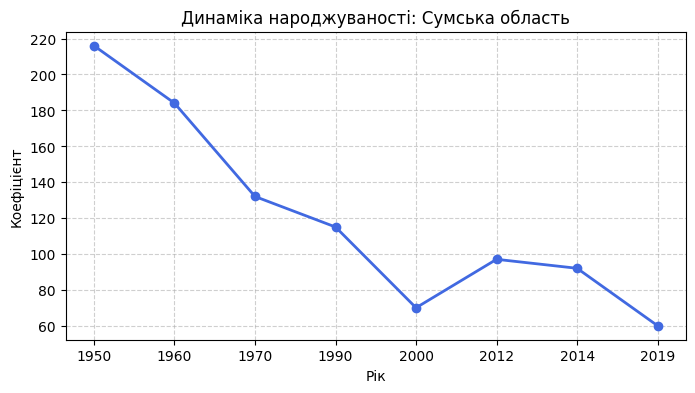

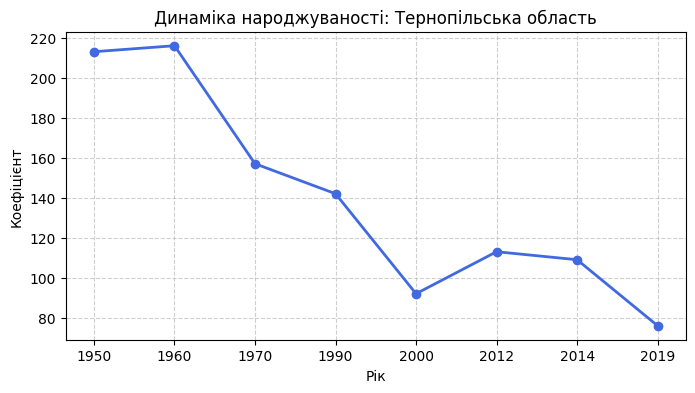

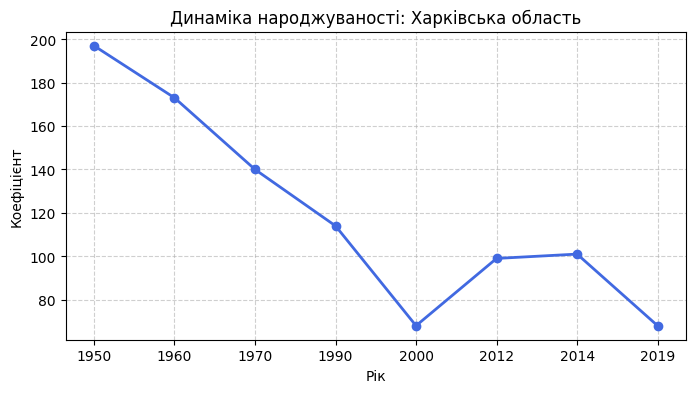

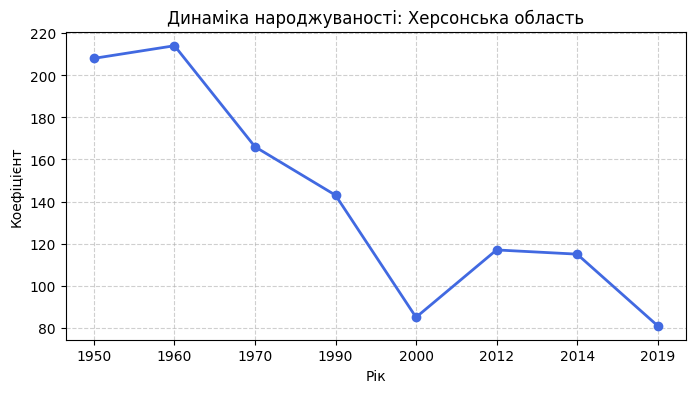

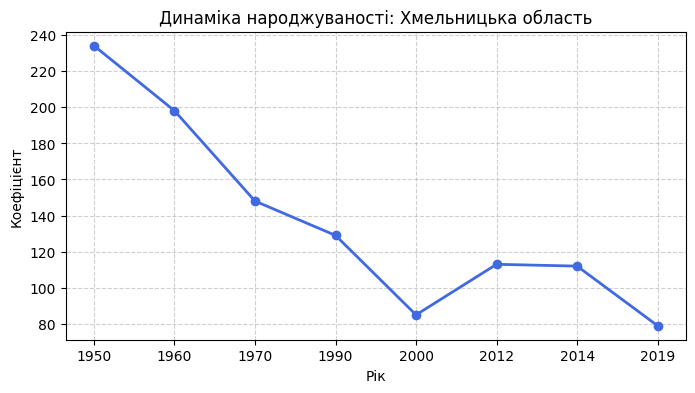

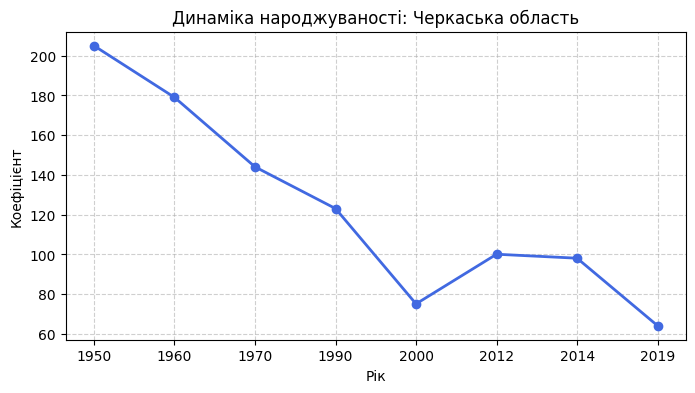

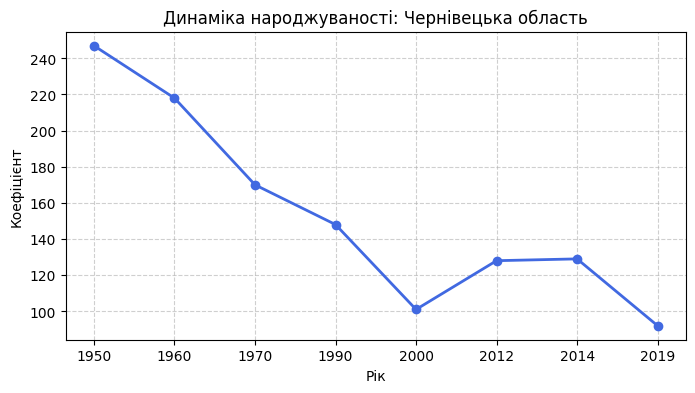

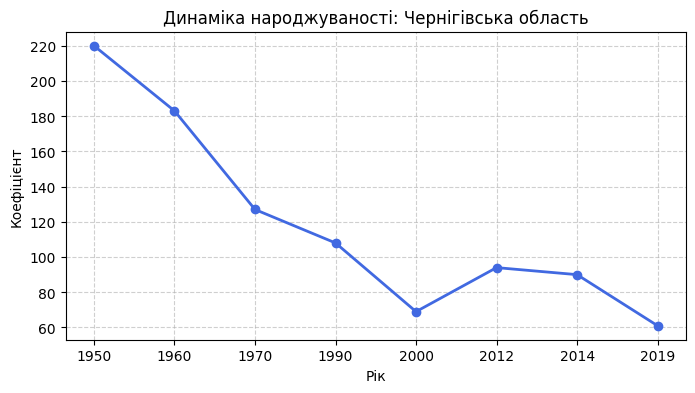

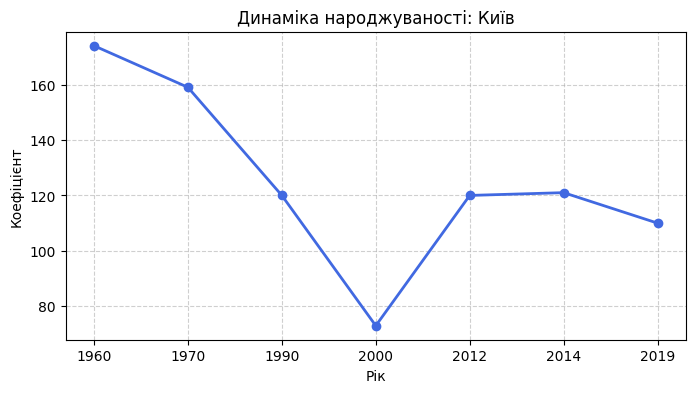

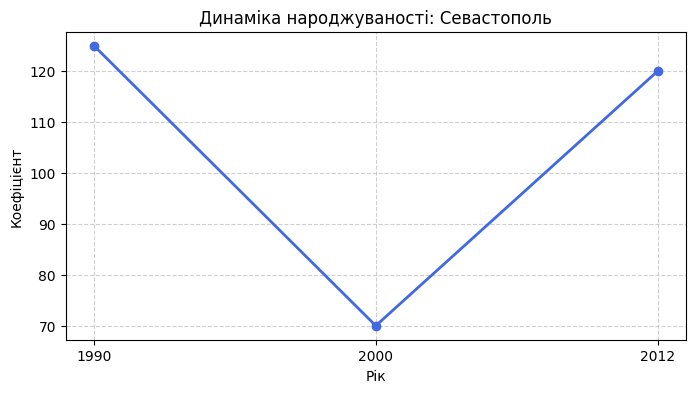

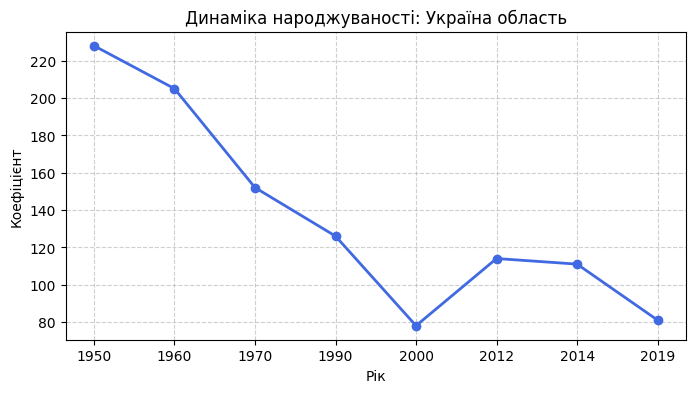

In [23]:
years = ['1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']

for _, row in df.iterrows():
    region_name = row['Регіон']
    if region_name in ['Київ', 'Севастополь'] or 'Крим' in region_name:
        title_name = region_name
    else:
        title_name = f'{region_name} область'

    plt.figure(figsize=(8, 4))
    values = [row[col] for col in years]
    plt.plot(years, values, marker='o', color='royalblue', linewidth=2)
    plt.title(f'Динаміка народжуваності: {title_name}')
    plt.xlabel('Рік')
    plt.ylabel('Коефіцієнт')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

Графік 4.  Аналіз та порівняння зміни народжуваності (1950 vs 2019)

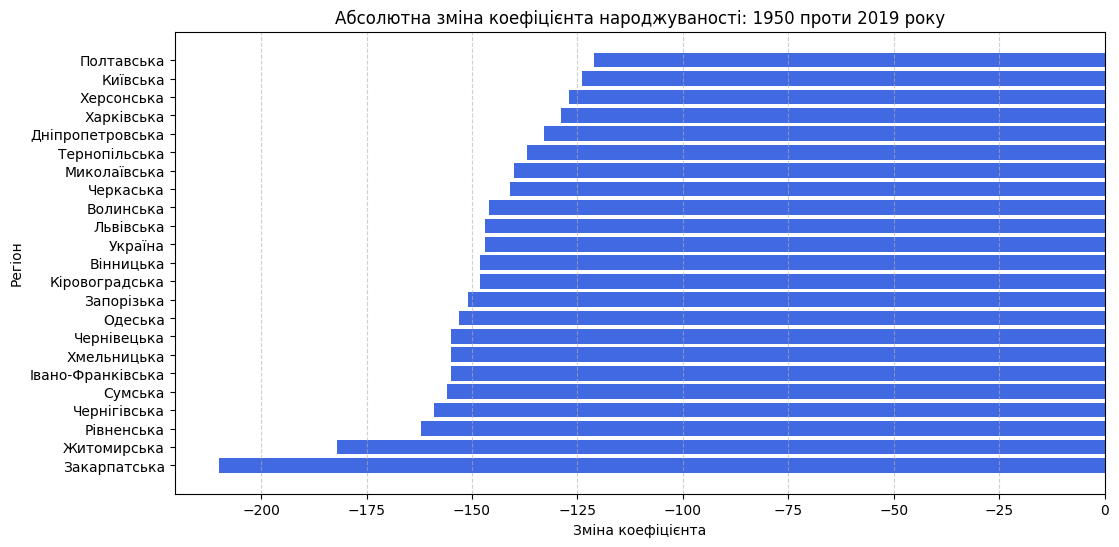

In [20]:
comparison_df = df[['Регіон', '1950', '2019']].dropna().copy()
comparison_df['Різниця'] = comparison_df['2019'] - comparison_df['1950']
comparison_df = comparison_df.sort_values(by='Різниця', ascending=True)

plt.figure(figsize=(12, 6))
plt.barh(comparison_df['Регіон'], comparison_df['Різниця'], color='royalblue')
plt.title('Абсолютна зміна коефіцієнта народжуваності: 1950 проти 2019 року')
plt.xlabel('Зміна коефіцієнта')
plt.ylabel('Регіон')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

Графік 5. Кореляційна матриця (аналіз зв'язку між роками)

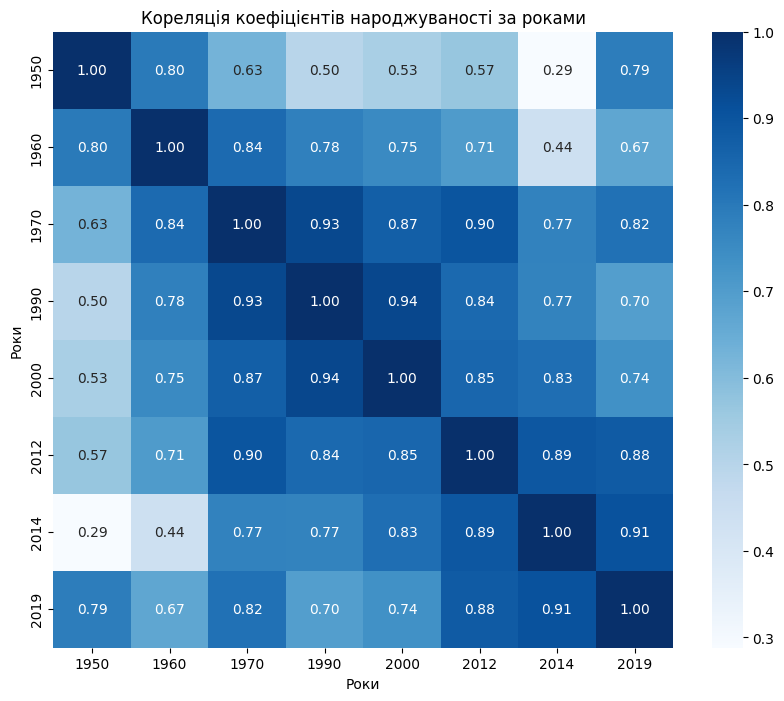

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Кореляція коефіцієнтів народжуваності за роками')
plt.xlabel('Роки')
plt.ylabel('Роки')
plt.show()

**Висновок.**
Аналіз демографічних даних свідчить про глибокі трансформації у рівні народжуваності в Україні за період з 1950 по 2019 рік.
Загальна динаміка демонструє тривале та виражене скорочення середнього коефіцієнта народжуваності. Найбільш інтенсивне зниження відбулося в другій половині XX століття, досягнувши історичного мінімуму близько 2000 року, після чого спостерігалися лише тимчасові та незначні періоди стабілізації.
Регіональний зріз станом на 2019 рік указує на збереження чіткого географічного дисбалансу. Вищі показники народжуваності спостерігаються в столиці та західних областях, зокрема в Рівненській, Закарпатській та Волинській. У той самий час найнижчі рівні зафіксовано в областях Північного та Східного регіонів, таких як Сумська та Чернігівська.
Порівняння показників 1950 та 2019 років підтверджує, що депопуляційні процеси охопили абсолютно всі регіони країни без винятку. При цьому найбільша абсолютна втрата коефіцієнта спостерігається саме в тих областях, які в середині минулого століття мали найвищий демографічний потенціал, зокрема в Закарпатській, Житомирській та Рівненській.